In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv('/content/car_price_prediction.csv')

# Display the first few rows to confirm it loaded correctly
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (19237, 18)

Column Names:
Index(['ID', 'Price', 'Levy', 'Manufacturer', 'Model', 'Prod. year',
       'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage',
       'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color',
       'Airbags'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  object 
 3   Manufacturer      19237 non-null  object 
 4   Model             19237 non-null  object 
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  object 
 7   Leather interior  19237 non-null  object 
 8   Fuel type         19237 non-null  object 
 9   Engine volume     19237 non-null  o

In [ ]:
# Check the first 5 rows
print("First 5 Rows:")
display(df.head())

# Check duplicate values
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check dataset information
print("\nDataset Information:")
df.info()

print("\nData cleaning completed successfully!")

First 5 Rows:


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4



Duplicate Rows: 313

Missing Values:
ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                18924 non-null  int64  
 1   Price             18924 non-null  int64  
 2   Levy              18924 non-null  object 
 3   Manufacturer      18924 non-null  object 
 4   Model             18924 non-null  object 
 5   Prod. year        18924 non-null  int64  
 6   Category          18924 non-null  object 
 7  

In [ ]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Dataset size
print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Column Names:
['ID', 'Price', 'Levy', 'Manufacturer', 'Model', 'Prod. year', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags']

Statistical Summary:


,ID,Price,Prod. year,Cylinders,Airbags
count,1.892400e+04,1.892400e+04,18924.000000,18924.000000,18924.000000
mean,4.557538e+07,1.858744e+04,2010.914236,4.580216,6.568379
std,9.375468e+05,1.921356e+05,5.665749,1.200223,4.322323
min,2.074688e+07,1.000000e+00,1939.000000,1.000000,0.000000
25%,4.569501e+07,5.331000e+03,2009.000000,4.000000,4.000000
50%,4.577191e+07,1.317200e+04,2012.000000,4.000000,6.000000
75%,4.580174e+07,2.206300e+04,2015.000000,4.000000,12.000000
max,4.581665e+07,2.630750e+07,2020.000000,16.000000,16.000000



Number of Rows: 18924
Number of Columns: 18


In [ ]:
# Average price
print("Average Price:", df['Price'].mean())

# Minimum price
print("Minimum Price:", df['Price'].min())

# Maximum price
print("Maximum Price:", df['Price'].max())

Average Price: 18587.435267385332
Minimum Price: 1
Maximum Price: 26307500


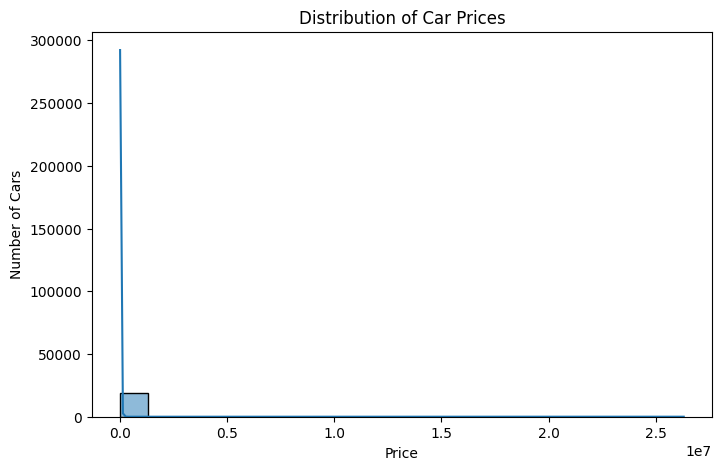

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Price'], bins=20, kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of Cars")

plt.show()

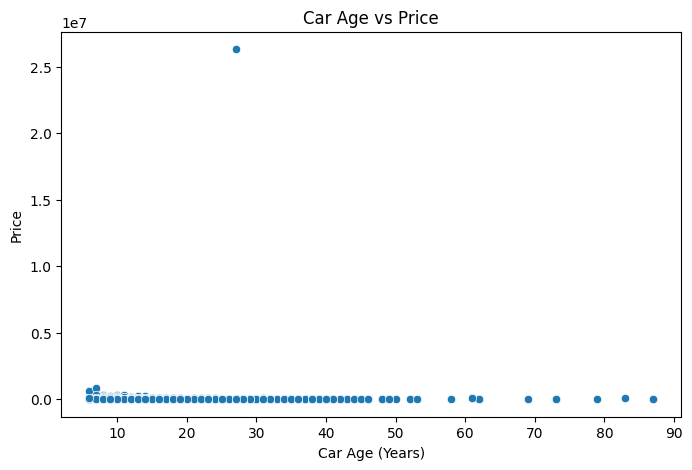

In [ ]:
# Calculate car age using 'Prod. year'
df['Car_Age'] = 2026 - df['Prod. year']

# Create a scatter plot using 'Car_Age' and 'Price'
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Car_Age', y='Price')

plt.title('Car Age vs Price')
plt.xlabel('Car Age (Years)')
plt.ylabel('Price')

plt.show()

Loading and cleaning df...


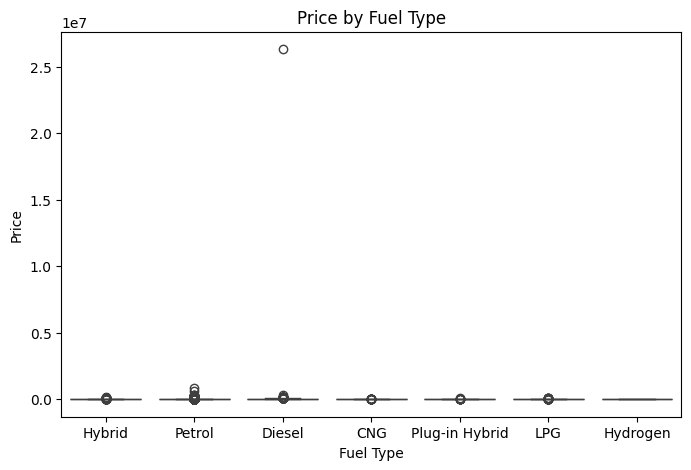

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Safely verify and retrieve df from memory, or load and clean it if missing
try:
    df_check = df
except NameError:
    print("Loading and cleaning df...")
    df = pd.read_csv('/content/car_price_prediction.csv')
    df.drop_duplicates(inplace=True)

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Fuel type', y='Price')

plt.title('Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Price')

plt.show()

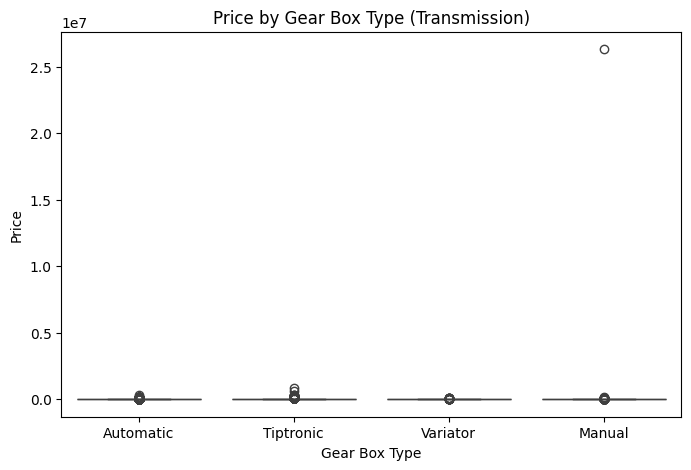

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Gear box type', y='Price')

plt.title('Price by Gear Box Type (Transmission)')
plt.xlabel('Gear Box Type')
plt.ylabel('Price')

plt.show()

In [ ]:
import pandas as pd

# Create a copy of the dataset
data_prep = df.copy()

# List of columns to drop to avoid high-cardinality feature explosion and training hangs
columns_to_drop = [
    'ID', 'Model', 'Manufacturer', 'Levy', 'Engine volume',
    'Mileage', 'Doors', 'Color', 'Car_Age'
]
data_prep.drop(columns=columns_to_drop, axis=1, inplace=True, errors='ignore')

# Convert remaining categorical columns (like 'Category', 'Fuel type', 'Gear box type', etc.) into numeric indicators
data_prep = pd.get_dummies(data_prep, drop_first=True, dtype=int)

# Separate features and target
X = data_prep.drop('Price', axis=1)
y = data_prep['Price']

print("Features prepared successfully!")
print("Reduced features shape:", X.shape)
print("Target shape:", y.shape)

Features prepared successfully!
Reduced features shape: (18924, 26)
Target shape: (18924,)


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Safely verify and retrieve X and y from memory, or reconstruct them if missing
try:
    X_check, y_check = X, y
except NameError:
    print("Rebuilding X and y datasets...")
    df_temp = pd.read_csv('/content/car_price_prediction.csv')
    df_temp.drop_duplicates(inplace=True)
    data_prep = df_temp.copy()
    data_prep.drop(['ID', 'Model', 'Car_Age'], axis=1, inplace=True, errors='ignore')
    data_prep = pd.get_dummies(data_prep, drop_first=True, dtype=int)
    X = data_prep.drop('Price', axis=1)
    y = data_prep['Price']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Data splitting completed successfully!")

Rebuilding X and y datasets...
Training data shape: (15139, 8457)
Testing data shape: (3785, 8457)
Data splitting completed successfully!


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Re-split training datasets using the newly optimized features
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the Linear Regression Model
print("Fitting the model on optimized features...")
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed successfully!")

Fitting the model on optimized features...
Model training completed successfully!


In [ ]:
# Predict prices for test data using the successfully trained model
y_pred = model.predict(X_test)

# Display actual and predicted prices
results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("Actual vs Predicted Car Prices:")
display(results.head(10))

Actual vs Predicted Car Prices:


,Actual Price,Predicted Price
0,11604,14805.956730
1,470,8434.160058
2,20162,16629.938221
3,7527,-4174.606962
4,18817,17493.573156
5,44003,25394.684302
6,21326,19681.499737
7,15681,27713.519064
8,6899,5779.017991
9,1333,14959.025662


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics using the generated predictions
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Score (%):", round(r2 * 100, 2), "%")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 12148.07
Mean Squared Error (MSE): 495494528.57
Root Mean Squared Error (RMSE): 22259.71
R2 Score: -0.4311
R2 Score (%): -43.11 %


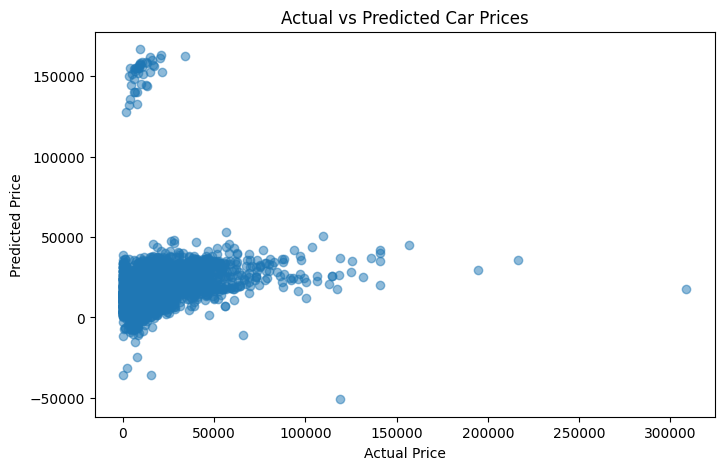

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")
plt.show()

In [ ]:
# Select one car from the test dataset
sample_car = X_test.iloc[[0]]

# Predict its price
predicted_price = model.predict(sample_car)[0]

print("Predicted Car Price:", round(predicted_price, 2))
print("Actual Car Price:", y_test.iloc[0])

Predicted Car Price: 14805.96
Actual Car Price: 11604


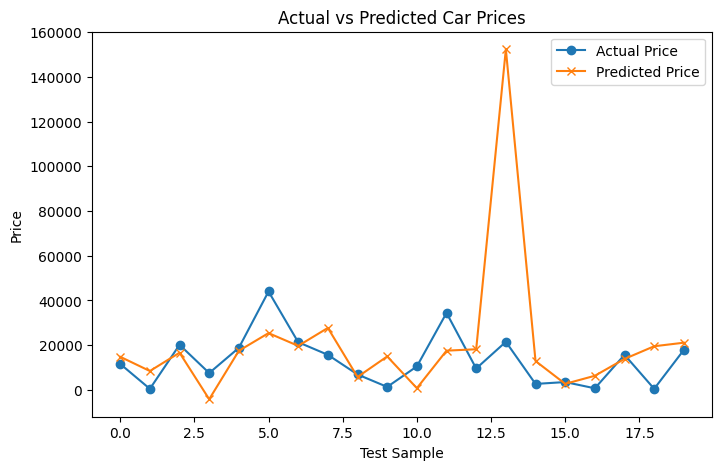

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(y_test.values[:20], marker='o', label='Actual Price')
plt.plot(y_pred[:20], marker='x', label='Predicted Price')

plt.title('Actual vs Predicted Car Prices')
plt.xlabel('Test Sample')
plt.ylabel('Price')
plt.legend()
plt.show()